In [ ]:
!pip install xgboost shap imbalanced-learn optuna

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
import xgboost as xgb
import shap
print("All tools successfully loaded!")

All tools successfully loaded!


In [15]:
from google.colab import files

uploaded = files.upload()

Saving Loan_Default.csv to Loan_Default.csv


In [17]:
import pandas as pd

# Replace 'your_file_name.csv' with your actual file name
df = pd.read_csv('Loan_Default.csv')
df.head()


,ID,year,loan_limit,Gender,approv_in_adv,loan_type,loan_purpose,Credit_Worthiness,open_credit,business_or_commercial,...,credit_type,Credit_Score,co-applicant_credit_type,age,submission_of_application,LTV,Region,Security_Type,Status,dtir1
0,24890,2019,cf,Sex Not Available,nopre,type1,p1,l1,nopc,nob/c,...,EXP,758,CIB,25-34,to_inst,98.728814,south,direct,1,45.0
1,24891,2019,cf,Male,nopre,type2,p1,l1,nopc,b/c,...,EQUI,552,EXP,55-64,to_inst,NaN,North,direct,1,NaN
2,24892,2019,cf,Male,pre,type1,p1,l1,nopc,nob/c,...,EXP,834,CIB,35-44,to_inst,80.019685,south,direct,0,46.0
3,24893,2019,cf,Male,nopre,type1,p4,l1,nopc,nob/c,...,EXP,587,CIB,45-54,not_inst,69.376900,North,direct,0,42.0
4,24894,2019,cf,Joint,pre,type1,p1,l1,nopc,nob/c,...,CRIF,602,EXP,25-34,not_inst,91.886544,North,direct,0,39.0


In [18]:
# Stage 2: Preprocessing with Automatic Binary Target Detection
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
import pandas as pd

# 1. Automatically locate the binary target column (2 unique values, e.g., 0/1 or Good/Bad)
binary_cols = [col for col in df.columns if df[col].nunique() == 2]

if not binary_cols:
    raise ValueError("No binary target column (with exactly 2 unique values) was found. Please check df.head().")

target_col = binary_cols[0]
print(f"Target column detected: '{target_col}'")

# 2. Clean missing values
df_clean = df.dropna(subset=[target_col]).copy()

X = df_clean.drop(columns=[target_col])
y = df_clean[target_col]

# Fill missing numerical values with median
X = X.fillna(X.median(numeric_only=True))

# One-hot encode categorical features
X = pd.get_dummies(X, drop_first=True)

# 3. Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 4. Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. Apply SMOTE exclusively on training data
smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train_scaled, y_train)

print("\n--- Stage 2 Complete ---")
print(f"Balanced Training Samples: {len(X_train_bal)}")
print(f"Test Set Samples: {len(X_test)}")

Target column detected: 'loan_limit'

--- Stage 2 Complete ---
Balanced Training Samples: 216556
Test Set Samples: 29066


In [19]:
# Stage 3: Fast XGBoost Training with Histogram Acceleration
from sklearn.preprocessing import LabelEncoder
import xgboost as xgb
from sklearn.metrics import classification_report, roc_auc_score

# 1. Encode target classes
le = LabelEncoder()
y_train_bal_encoded = le.fit_transform(y_train_bal)
y_test_encoded = le.transform(y_test)

# 2. Initialize XGBoost Classifier with 'hist' tree_method
model = xgb.XGBClassifier(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=5,
    tree_method='hist',  # Drastically speeds up training on 300k+ rows
    random_state=42,
    eval_metric='logloss',
    n_jobs=-1
)

# 3. Train model on SMOTE-balanced features
print("Training model...")
model.fit(X_train_bal, y_train_bal_encoded)

# 4. Make predictions on isolated test set
y_pred = model.predict(X_test_scaled)
y_proba = model.predict_proba(X_test_scaled)[:, 1]

print("\n--- Stage 3: Model Performance ---")
print(classification_report(y_test_encoded, y_pred))
print(f"ROC-AUC Score: {roc_auc_score(y_test_encoded, y_proba):.4f}")

Training model...

--- Stage 3: Model Performance ---
              precision    recall  f1-score   support

           0       0.96      0.94      0.95     27070
           1       0.39      0.49      0.44      1996

    accuracy                           0.91     29066
   macro avg       0.68      0.72      0.70     29066
weighted avg       0.92      0.91      0.92     29066

ROC-AUC Score: 0.8352


--- Generating SHAP Beeswarm Plot ---


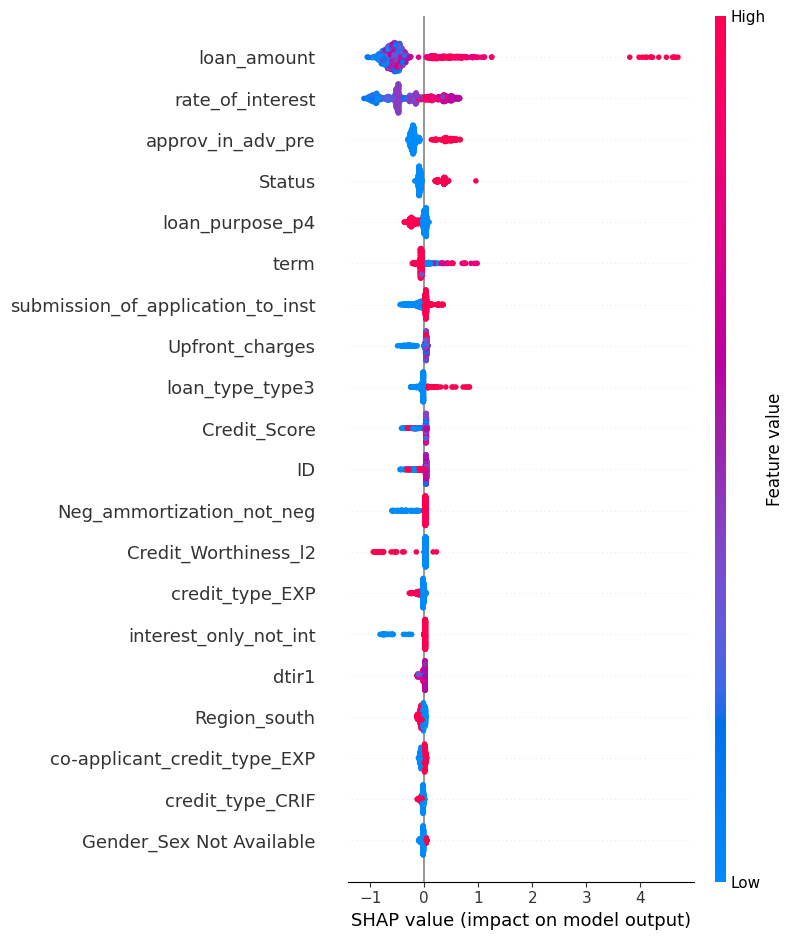

--- Generating SHAP Bar Plot ---


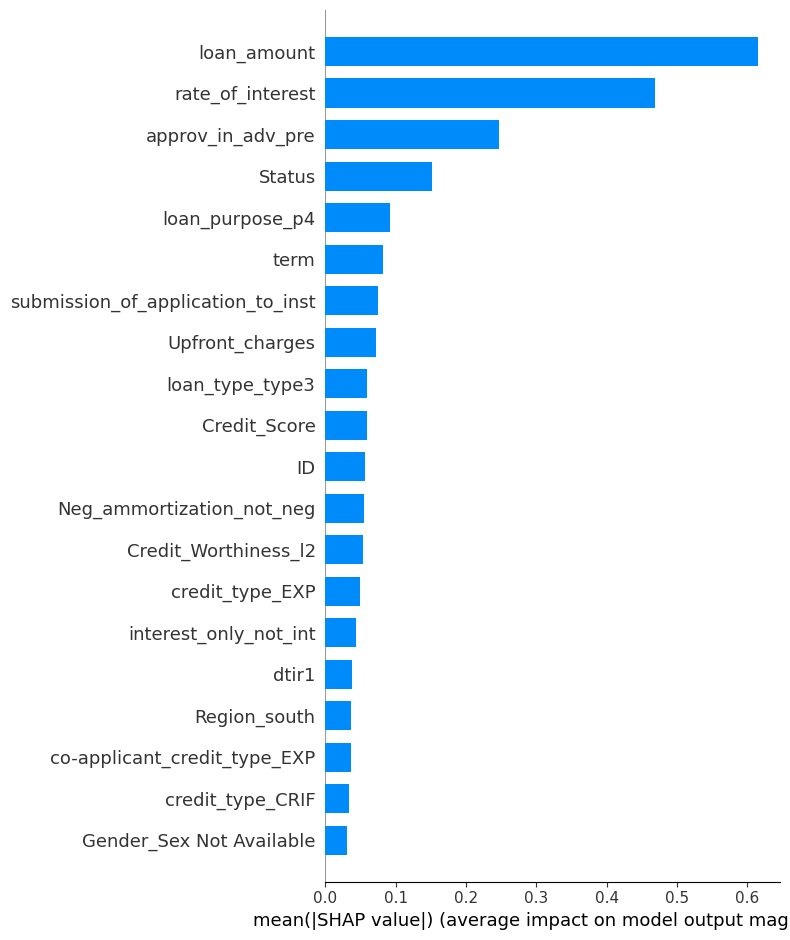

In [20]:
# Stage 4: SHAP Explainability Visualization (Fixed)
import shap

# 1. Take a sample of 1,000 instances directly as a NumPy array (matching model format)
X_sample_scaled = X_test_scaled[:1000]

# 2. Calculate SHAP values using TreeExplainer
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_sample_scaled)

# 3. Generate SHAP Beeswarm Plot
print("--- Generating SHAP Beeswarm Plot ---")
shap.summary_plot(shap_values, X_sample_scaled, feature_names=X.columns)

# 4. Generate SHAP Global Feature Importance Bar Plot
print("--- Generating SHAP Bar Plot ---")
shap.summary_plot(shap_values, X_sample_scaled, feature_names=X.columns, plot_type="bar")

In [23]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import matplotlib.pyplot as plt
import shap
import pandas as pd

# 1. Grab a template applicant from your existing test data
if isinstance(X_test, pd.DataFrame):
    baseline_sample = X_test.iloc[[0]].copy()
else:
    baseline_sample = X_test[0:1].copy()

# 2. Create the UI Sliders (Simplified for a clean demo)
loan_slider = widgets.FloatSlider(value=24000, min=1000, max=50000, step=500, description='Loan Amt:')
rate_slider = widgets.FloatSlider(value=24.0, min=1.0, max=30.0, step=0.5, description='Rate (%):')
button = widgets.Button(description="Assess Risk", button_style='success')
output = widgets.Output()

# 3. Define the Assessment Function
def assess_applicant(b):
    with output:
        clear_output(wait=True)

        # Copy the template applicant
        sample = baseline_sample.copy()

        # Update the first two features with the new slider values
        if isinstance(sample, pd.DataFrame):
            sample['loan_amount'] = loan_slider.value
            sample['rate_of_interest'] = rate_slider.value
        else:
            sample[0, 0] = loan_slider.value
            sample[0, 1] = rate_slider.value

        # Predict Risk
        default_prob = model.predict_proba(sample)[0][1]
        decision = "🔴 HIGH RISK (Rejected)" if default_prob >= 0.5 else "🟢 LOW RISK (Approved)"

        print(f"--- REAL-TIME DECISION ---")
        print(f"Outcome: {decision}")
        print(f"Probability of Default: {default_prob * 100:.2f}%\n")

        # Generate SHAP Waterfall Plot
        try:
            # FIX 1: Convert to NumPy array to bypass XGBoost's strict column name rules
            sample_array = sample.values if isinstance(sample, pd.DataFrame) else sample
            shap_val = explainer(sample_array)

            # FIX 2: Re-attach cleaned feature names for the plot labels
            if isinstance(sample, pd.DataFrame):
                clean_cols = sample.columns.str.replace(r'[\[\]<>]', '_', regex=True)
                shap_val.feature_names = list(clean_cols)

            plt.close('all')
            fig = plt.figure(figsize=(8, 4))
            shap.plots.waterfall(shap_val[0], max_display=6)
            plt.show()
        except Exception as e:
            print(f"SHAP Plot Error: {e}")

# 4. Display the UI
button.on_click(assess_applicant)
display(widgets.VBox([loan_slider, rate_slider, button, output]))